# Benders Decomposition with Pyomo
A worked tutorial on **duality, extreme points, extreme rays, feasibility/optimality cuts, block-angular structure, and the iterative decomposition procedure**.

The notebook uses small numerical examples so that every step can be inspected.

## 0. Setup

Install if needed:

```bash
pip install pyomo highspy numpy pandas matplotlib
```

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyomo.environ as pyo

solver = pyo.SolverFactory("appsi_highs")
if not solver.available(exception_flag=False):
    raise RuntimeError("Install HiGHS: pip install highspy")

solver.config.load_solution=False

# 1. The Benders idea

Start with

$\min_{x,y}\ c^Tx+d^Ty$

subject to

$
Ax\ge b,\qquad Ex+Fy\ge h,\qquad x\in X,\ y\ge0.
$

Treat \(x\) as master variables. For fixed \(x=\bar x\),

$
Q(\bar x)=\min_y\{d^Ty:Fy\ge h-E\bar x,\ y\ge0\}.
$

The original problem is

$
\min_{x\in X}\ c^Tx+Q(x).
$

Benders replaces \(Q(x)\) by a master variable \(\theta\):

$
\min_{x,\theta}\ c^Tx+\theta.
$

The master progressively learns a lower description of \(Q(x)\) through cuts.

# 2. Numerical example

Consider

$
\begin{aligned}
\min\quad &2x+y_1+3y_2\\
\text{s.t.}\quad
&y_1+y_2\ge4-x,\\
&2y_1+y_2\ge5-x,\\
&x,y_1,y_2\ge0.
\end{aligned}
$

First solve it monolithically.

In [17]:
m = pyo.ConcreteModel()
m.x = pyo.Var(domain=pyo.NonNegativeReals)
m.y1 = pyo.Var(domain=pyo.NonNegativeReals)
m.y2 = pyo.Var(domain=pyo.NonNegativeReals)
m.c1 = pyo.Constraint(expr=m.y1+m.y2 >= 4-m.x)
m.c2 = pyo.Constraint(expr=2*m.y1+m.y2 >= 5-m.x)
m.obj = pyo.Objective(expr=2*m.x+m.y1+3*m.y2)
solver.solve(m)
print("x =", pyo.value(m.x))
print("y1 =", pyo.value(m.y1))
print("y2 =", pyo.value(m.y2))
print("objective =", pyo.value(m.obj))


x = 0.0
y1 = 4.0
y2 = 0.0
objective = 4.0


# 3. The subproblem and its dual

For fixed \(x\),

$
Q(x)=\min_{y\ge0}\{d^Ty:Fy\ge h-Ex\}.
$

Its dual is

$
\max_{\pi\ge0}\{(h-Ex)^T\pi:F^T\pi\le d\}.
$

The crucial observation is that the dual feasible region

$
\Pi=\{\pi\ge0:F^T\pi\le d\}
$

does **not** depend on \(x\).

Every dual-feasible point gives

$
Q(x)\ge(h-Ex)^T\pi.
$

If \(\pi^k\) is an optimal dual solution for \(x^k\), then

$
\boxed{\theta\ge(h-Ex)^T\pi^k}
$

is a Benders optimality cut.

In [18]:
def solve_sp(x_value):
    sp = pyo.ConcreteModel()
    sp.y1 = pyo.Var(domain=pyo.NonNegativeReals)
    sp.y2 = pyo.Var(domain=pyo.NonNegativeReals)
    sp.c1 = pyo.Constraint(expr=sp.y1+sp.y2 >= 4-x_value)
    sp.c2 = pyo.Constraint(expr=2*sp.y1+sp.y2 >= 5-x_value)
    sp.obj = pyo.Objective(expr=sp.y1+3*sp.y2)
    sp.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)
    r = solver.solve(sp)
    return {
        "x": x_value,
        "Q": pyo.value(sp.obj),
        "y1": pyo.value(sp.y1),
        "y2": pyo.value(sp.y2),
        "pi1": sp.dual[sp.c1],
        "pi2": sp.dual[sp.c2],
        "status": str(r.solver.termination_condition)
    }

pd.DataFrame(solve_sp(x) for x in np.arange(0, 5.1, .5))


,x,Q,y1,y2,pi1,pi2,status
0,0.0,4.00,4.00,0.0,1.0,-0.0,optimal
1,0.5,3.50,3.50,0.0,1.0,-0.0,optimal
2,1.0,3.00,3.00,0.0,1.0,-0.0,optimal
3,1.5,2.50,2.50,0.0,1.0,-0.0,optimal
4,2.0,2.00,2.00,0.0,1.0,-0.0,optimal
5,2.5,1.50,1.50,0.0,1.0,-0.0,optimal
6,3.0,1.00,1.00,0.0,-0.0,0.5,optimal
7,3.5,0.75,0.75,0.0,-0.0,0.5,optimal
8,4.0,0.50,0.50,0.0,-0.0,0.5,optimal
9,4.5,0.25,0.25,0.0,-0.0,0.5,optimal


# 4. Extreme points

For this example the dual is

$
\begin{aligned}
\max\quad &(4-x)\pi_1+(5-x)\pi_2\\
\text{s.t.}\quad
&\pi_1+2\pi_2\le1,\\
&\pi_1+\pi_2\le3,\\
&\pi_1,\pi_2\ge0.
\end{aligned}
$

A finite LP optimum can be attained at an extreme point of the dual polyhedron.

Thus

$
Q(x)=\max_{\pi\in\operatorname{ext}(\Pi)}
(h-Ex)^T\pi.
$

Every relevant extreme point is an affine piece of the recourse function.

For example, \(\pi=(1,0)\) produces

$
\theta\ge4-x.
$

A point \(\pi=(0,\tfrac12)\) produces

$
\theta\ge2.5-\tfrac12x.
$

The recourse function is the upper envelope of these affine functions.

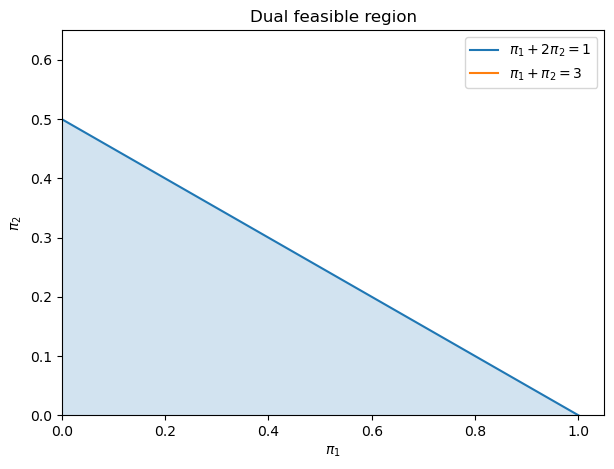

In [19]:
pi1 = np.linspace(0, 1.05, 400)
b1 = (1-pi1)/2
b2 = 3-pi1

fig, ax = plt.subplots(figsize=(7,5))
ax.plot(pi1, b1, label=r"$\pi_1+2\pi_2=1$")
ax.plot(pi1, b2, label=r"$\pi_1+\pi_2=3$")
ax.fill_between(pi1, 0, np.maximum(0,np.minimum(b1,b2)), alpha=.2)
ax.set(xlim=(0,1.05), ylim=(0,.65), xlabel=r"$\pi_1$", ylabel=r"$\pi_2$")
ax.set_title("Dual feasible region")
ax.legend()
plt.show()


# 5. Extreme rays and feasibility cuts

Optimality cuts use **extreme points**. Feasibility cuts use **extreme rays**.

An extreme ray \(r\) of the dual recession cone satisfies

$
r\ge0,\qquad F^Tr\le0.
$

If

$
(h-Ex)^Tr>0,
$

the dual is unbounded in direction \(r\), which certifies primal infeasibility.

Therefore a feasible master solution must satisfy

$
\boxed{(h-Ex)^Tr\le0}.
$

This is the Benders feasibility cut.

## 5.1 Constructive infeasibility example

Consider

$
\begin{aligned}
\min_y\quad&y\\
\text{s.t.}\quad
&y\ge1-x,\\
&-y\ge1-x,\\
&y\ge0.
\end{aligned}
$

These constraints imply

$
1-x\le y\le x-1,
$

so feasibility requires

$
x\ge1.
$

The important lesson is that a general Benders implementation must distinguish:

| Subproblem status | Geometric object | Master action |
|---|---|---|
| feasible + bounded | dual extreme point | optimality cut |
| infeasible | dual extreme ray | feasibility cut |

In [21]:
def feasibility_sp(x):
    sp = pyo.ConcreteModel()
    sp.y = pyo.Var(domain=pyo.NonNegativeReals)
    sp.c1 = pyo.Constraint(expr=sp.y >= 1-x)
    sp.c2 = pyo.Constraint(expr=-sp.y >= 1-x)
    sp.obj = pyo.Objective(expr=sp.y)
    return solver.solve(sp, load_solutions=False).solver.termination_condition

for x in [0,.5,1,1.5,2]:
    print(f"x={x:3.1f}:", feasibility_sp(x))


x=0.0: infeasible
x=0.5: infeasible
x=1.0: optimal
x=1.5: optimal
x=2.0: optimal


# 6. Block-angular structure

A canonical block-angular matrix is

$
\begin{bmatrix}
A&0&0&0\\
E_1&F_1&0&0\\
E_2&0&F_2&0\\
E_3&0&0&F_3
\end{bmatrix}.
$

Fixing \(x\) makes the scenario blocks independent:

$
Q(x)=Q_1(x)+Q_2(x)+Q_3(x).
$

This is the structure behind many stochastic programming, network design, facility location, capacity planning, and interdiction applications.

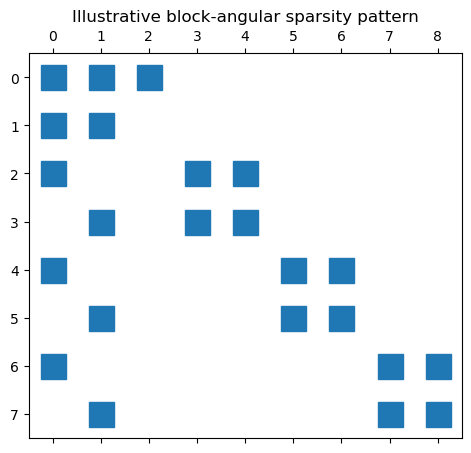

In [22]:
A = np.array([
[1,1,1,0,0,0,0,0,0],
[1,1,0,0,0,0,0,0,0],
[1,0,0,1,1,0,0,0,0],
[0,1,0,1,1,0,0,0,0],
[1,0,0,0,0,1,1,0,0],
[0,1,0,0,0,1,1,0,0],
[1,0,0,0,0,0,0,1,1],
[0,1,0,0,0,0,0,1,1],
])
fig, ax = plt.subplots(figsize=(8,5))
ax.spy(A, markersize=18)
ax.set_title("Illustrative block-angular sparsity pattern")
plt.show()


# 7. Staircase / angular structures

Block-angular structure gives independent subproblems after fixing \(x\).

A staircase structure can instead look like

$
\begin{bmatrix}
A_1&B_1&0\\
0&A_2&B_2\\
0&0&A_3
\end{bmatrix}.
$

Neighboring blocks interact, so decomposition is less independent.

The useful principle is:

> Benders is attractive when fixing a subset of variables makes the remaining problem separable or substantially easier.

# 8. The Benders master

The master is

$
\begin{aligned}
\min_{x,\theta}\quad&c^Tx+\theta\\
\text{s.t.}\quad&x\in X,\\
&\theta\ge h^T\pi^k-x^TE^T\pi^k,\quad k\in\mathcal K.
\end{aligned}
$

Initially \(\theta\) may have only a valid lower bound, e.g.

$
\theta\ge0.
$

At each iteration:

1. solve master;
2. obtain \(x^k\);
3. solve subproblem;
4. obtain a dual point or ray;
5. add a cut;
6. update bounds;
7. repeat.

In [23]:
def build_master():
    m = pyo.ConcreteModel()
    m.x = pyo.Var(domain=pyo.NonNegativeReals)
    m.theta = pyo.Var(domain=pyo.NonNegativeReals)
    m.cuts = pyo.ConstraintList()
    m.obj = pyo.Objective(expr=2*m.x+m.theta)
    return m

def benders(max_iter=20, tol=1e-7):
    master = build_master()
    LB, UB = -np.inf, np.inf
    rows = []

    for k in range(1,max_iter+1):
        solver.solve(master)
        xk = pyo.value(master.x)
        thetak = pyo.value(master.theta)
        LB = pyo.value(master.obj)

        sp = solve_sp(xk)
        Q = sp["Q"]
        UB = min(UB, 2*xk+Q)

        # Optimality cut:
        master.cuts.add(master.theta >= (4-master.x)*sp["pi1"] + (5-master.x)*sp["pi2"])

        gap = UB-LB
        rows.append([k,xk,thetak,Q,sp["pi1"],sp["pi2"],LB,UB,gap])

        print(f"iter {k:2d}: x={xk:8.4f}, " f"LB={LB:8.4f}, UB={UB:8.4f}, gap={gap:8.4g}")

        if gap <= tol:
            break

    return master, pd.DataFrame(rows, columns=["iteration","x","theta","Q","pi1","pi2","LB","UB","gap"])

master, history = benders()
history


iter  1: x=  0.0000, LB=  0.0000, UB=  4.0000, gap=       4
iter  2: x=  0.0000, LB=  4.0000, UB=  4.0000, gap=       0


,iteration,x,theta,Q,pi1,pi2,LB,UB,gap
0,1,0.0,0.0,4.0,1.0,-0.0,0.0,4.0,4.0
1,2,0.0,4.0,4.0,1.0,-0.0,4.0,4.0,0.0


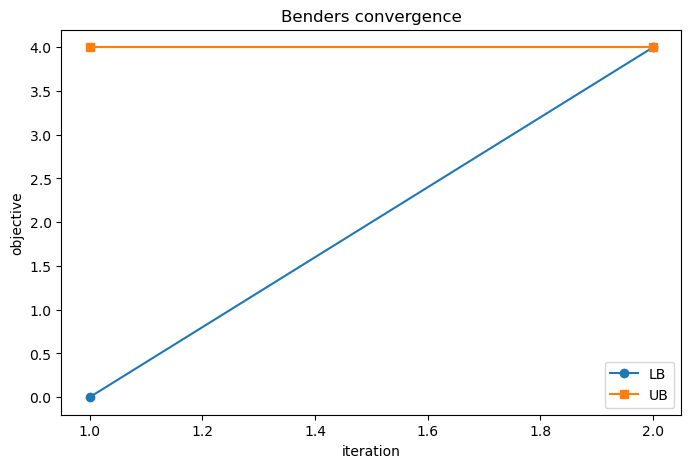

In [24]:
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(history["iteration"], history["LB"], marker="o", label="LB")
ax.plot(history["iteration"], history["UB"], marker="s", label="UB")
ax.set(xlabel="iteration", ylabel="objective", title="Benders convergence")
ax.legend()
plt.show()


# 9. Binary master variables

Benders is especially useful when the master contains binary/integer strategic decisions:

$
x_j\in\{0,1\}.
$

Examples include facility opening, edge selection, resource activation, and interdiction decisions.

The decomposition becomes

$
\text{MILP master}
\quad+\quad
\text{LP recourse}.
$

The master handles the combinatorial decisions while the subproblem handles the operational response.

In [25]:
def binary_master_skeleton():
    m = pyo.ConcreteModel()
    m.x = pyo.Var(range(3), domain=pyo.Binary)
    m.theta = pyo.Var(domain=pyo.NonNegativeReals)
    m.cuts = pyo.ConstraintList()
    m.obj = pyo.Objective(expr=5*m.x[0]+4*m.x[1]+6*m.x[2]+m.theta)
    return m

binary_master_skeleton().pprint()


2 Var Declarations
    theta : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  None :  None : False :  True : NonNegativeReals
    x : Size=3, Index={0, 1, 2}
        Key : Lower : Value : Upper : Fixed : Stale : Domain
          0 :     0 :  None :     1 : False :  True : Binary
          1 :     0 :  None :     1 : False :  True : Binary
          2 :     0 :  None :     1 : False :  True : Binary

1 Objective Declarations
    obj : Size=1, Index=None, Active=True
        Key  : Active : Sense    : Expression
        None :   True : minimize : 5*x[0] + 4*x[1] + 6*x[2] + theta

1 Constraint Declarations
    cuts : Size=0, Index={}, Active=True
        Key : Lower : Body : Upper : Active

4 Declarations: x theta cuts obj


# 10. Multi-cut Benders

If

$
Q(x)=\sum_{s=1}^S Q_s(x),
$

then each scenario has its own dual solution \(\pi_s^k\).

**Single-cut:**

$
\theta\ge
\sum_s
\left(h_s^T\pi_s^k-x^TE_s^T\pi_s^k\right).
$

**Multi-cut:**

$
\theta=\sum_s\theta_s
$

and

$
\theta_s\ge
h_s^T\pi_s^k-x^TE_s^T\pi_s^k.
$

Multi-cut Benders gives the master more scenario-specific information per iteration, at the cost of a larger master.

# 11. Bounds and convergence

For minimization,

$
LB_k\le z^\star\le UB_k.
$

The master objective supplies the lower bound.

A feasible subproblem solution gives an incumbent:

$
UB_k=
\min\{UB_{k-1},c^Tx^k+Q(x^k)\}.
$

Typical termination:

$
UB-LB\le\epsilon
$

or

$
\frac{UB-LB}{\max(1,|UB|)}\le\epsilon.
$

For MILP masters, also record the solver's MIP bound and incumbent when diagnosing convergence.

# 12. Degeneracy and stronger cuts

The dual optimum may not be unique.

Two dual optimal solutions can have the same value at \(x^k\) but produce very different cuts away from \(x^k\).

This can make basic Benders slow.

A common strengthening approach is to select a better point on the optimal dual face. This leads to **Pareto-optimal Benders cuts**, including the Magnanti-Wong procedure.

A sensible implementation progression is:

1. verify ordinary Benders;
2. measure iteration/cut counts;
3. try multi-cut Benders;
4. then investigate Pareto strengthening.

# 13. Benders versus Dantzig-Wolfe

Both exploit polyhedral structure.

**Benders**
- partitions variables;
- solves a subproblem;
- uses its dual;
- adds rows/cuts.

**Dantzig-Wolfe**
- partitions the feasible region;
- uses extreme points/rays;
- adds columns.

Mnemonic:

$
\boxed{\text{Benders = rows}}
\qquad
\boxed{\text{Dantzig-Wolfe = columns}}


# 14. Practical Pyomo checklist

Before applying Benders to a larger model:

- Identify master variables \(x\).
- Identify recourse variables \(y\).
- Verify that fixing \(x\) leaves a valid subproblem.
- Derive the subproblem dual independently.
- Check constraint orientation and dual signs.
- Give \(\theta\) a valid initial lower bound.
- Import duals only from feasible bounded LP solves.
- Handle infeasibility separately.
- Generate feasibility cuts from dual rays.
- Track lower and upper bounds.
- Detect duplicate/near-duplicate cuts.
- Use explicit numerical tolerances.
- Validate against the monolithic formulation on small instances.
- Record master time, subproblem time, iteration count, cut count, and gap.

The central loop is

$
\boxed{
x^k
\rightarrow
\text{subproblem}
\rightarrow
\text{dual point/ray}
\rightarrow
\text{cut}
\rightarrow
\text{new master}
}.
$

